# Etapas y el aumento significativo del riesgo de crédito

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- comparar la PD que tenía un préstamo en su origen con la PD que tiene a la fecha de reporte sobre la misma ventana, y anualizar ambas para que préstamos de distinta vida restante sean comparables;
- aplicar la regla relativa y absoluta de aumento significativo del riesgo de crédito (SICR) con el respaldo del triple, y decir qué hace cada parámetro de la política con el número de préstamos en la Etapa 2;
- asignar una etapa con las presunciones de 30 y 90 días de mora, la refinanciación, la lista de vigilancia y la exención de bajo riesgo de crédito, y leer qué disparador actuó y por qué tuvo precedencia;
- mantener un préstamo curado en la Etapa 2 durante un período de prueba, y reportar el objetivo de una transferencia colectiva sin sumarlo a la cobertura;
- leer los flujos entre etapas y la cobertura por etapa de una fecha de reporte versionada, y comparar una fecha tranquila con una de estrés.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 (préstamos 7(a) a pequeñas empresas de la SBA como gemelo público de una cartera hipotecaria; Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`) en dos fechas de reporte: 2008-12-31, en plena crisis financiera, y 2019-12-31, un año tranquilo. Cada artefacto guarda, además de las estructuras de plazos del cuaderno 01:

- `outputs.settings.sicr`: la política de etapas que usó el pipeline (el calendario de multiplicadores, el piso absoluto, la razón del triple, los 30 y 90 días);
- `outputs.account_curves`: una muestra de 40 cuentas con su PD acumulada desde el origen y desde la fecha de reporte, trimestre a trimestre durante tres años;
- `outputs.sicr_points`: una muestra de 400 cuentas con su PD anualizada en el origen y ahora, la etapa y el disparador que asignó el pipeline;
- `outputs.stage_flows` y `outputs.stage_summary`: el movimiento de toda la cartera entre los dos cierres de año y sus totales por etapa.

**Lo que el archivo no tiene:** historia de mora, refinanciación ni lista de vigilancia (hallazgo `F-NO-DELINQUENCY`). En el C06 solo la prueba cuantitativa de SICR puede pasar un préstamo a la Etapa 2, y los días de mora son cero. Los casos de los disparadores cualitativos de abajo son por eso **cuentas construidas**, rotuladas como tales, para mostrar cómo decide el motor.

La celda siguiente carga ambos artefactos, construye la `StagingPolicy` del motor con los ajustes versionados e imprime la política y las versiones del motor.

In [2]:
# Cargar las dos fechas de reporte y construir la política de etapas del motor desde los ajustes versionados
from riskvalidation.provisions import staging, term_structure as tsm

ROOT = Path("../../..").resolve()
LANG = "es"


def read(name):
    return json.loads((ROOT / "data" / "derived" / "C06" / name).read_text(encoding="utf-8"))


crisis, calm = read("rd-2008-12.json"), read("rd-2019-12.json")
out = crisis["outputs"]
sicr = out["settings"]["sicr"]
policy = staging.StagingPolicy(
    multiplier_schedule=tuple((row["pd_origination_upper"], row["multiplier"]) for row in sicr["multiplier_schedule"]),
    absolute_floor=sicr["absolute_floor"], threefold_ratio=sicr["threefold_ratio"],
    dpd_backstop=sicr["dpd_backstop"], default_dpd=sicr["default_dpd"],
    probation_months=out["settings"]["probation_months"], low_credit_risk_pd=sicr["low_credit_risk_pd"],
)
print("calendario de multiplicadores (PD de origen hasta, multiplicador):", policy.multiplier_schedule)
print("piso absoluto:", policy.absolute_floor, "| razón del triple:", policy.threefold_ratio, "| dpd:", policy.dpd_backstop, policy.default_dpd)
print("calculado por el motor:", crisis["provenance"]["riskvalidation_version"], calm["provenance"]["riskvalidation_version"], "| motor instalado:", md.version("riskvalidation"))
print("hallazgo:", [f["title"][LANG] for f in crisis["findings"] if f["id"] == "F-NO-DELINQUENCY"][0])

calendario de multiplicadores (PD de origen hasta, multiplicador): ((0.01, 4.0), (0.05, 2.5), (0.5, 1.5))
piso absoluto: 0.005 | razón del triple: 3.0 | dpd: 30 90
calculado por el motor: 0.5.0 0.5.0 | motor instalado: 0.8.1
hallazgo: El archivo SBA no tiene historia de mora, refinanciación ni lista de vigilancia: solo la prueba cuantitativa de SICR puede pasar un préstamo a Etapa 2, y la Etapa 3 no tiene saldo en una fecha


## Método

La asignación de etapas de IFRS 9 compara el riesgo de crédito de ahora con el riesgo en el reconocimiento inicial (IFRS 9 5.5.3, 5.5.9). La norma no prescribe cómo. Contraste sigue la práctica que encontró su investigación (GPPC 2016, sección 2.7.2; BCBS d350, anexo A26; EBA/Rep/2021/35 y EBA/Rep/2023/36 párrafo 32). Cuatro elementos:

**1. La misma ventana.** La expectativa de origen para la ventana restante es la PD a futuro de la estructura de plazos estimada en el origen, $PD^{\mathrm{orig}}(a, a+H) = \frac{S^{(t_0)}(a) - S^{(t_0)}(a+H)}{S^{(t_0)}(a)}$, y la estimación actual es $PD^{\mathrm{rep}}(0, H)$ de la estructura de plazos a la fecha de reporte. Ambas se anualizan para que préstamos de distinta vida restante sean comparables: $\overline{PD} = 1 - (1 - PD)^{1/H_{\mathrm{años}}}$. La forma geométrica es la convención documentada de Contraste; la EBA dice que compara PD de vida completa anualizadas y, en los pasajes leídos, no enuncia la fórmula (NO VERIFICADO como la de la EBA).

**2. La regla cuantitativa** (relativa y absoluta, con el respaldo del triple), con $m(\cdot)$ un multiplicador que no sube con la PD de origen y $\delta$ un piso absoluto:

$$\mathrm{SICR} = \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge m(\overline{PD}^{\mathrm{orig}}) \;\wedge\; \overline{PD}^{\mathrm{rep}} - \overline{PD}^{\mathrm{orig}} \ge \delta\Bigr] \;\vee\; \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge 3\Bigr]$$

**3. La etapa.** Etapa 3 si el préstamo está en incumplimiento (incumplido, o con 90 o más días de mora, B5.5.37); si no, Etapa 2 si actúa algún disparador (más de 30 días de mora como presunción refutable, 5.5.11; refinanciación; lista de vigilancia; una transferencia colectiva; la regla cuantitativa); si no, Etapa 1. La exención de bajo riesgo de crédito (5.5.10) suprime solo los dos disparadores cuantitativos. El motor fija la precedencia de los disparadores y devuelve el que decidió.

**4. El camino de vuelta y la mirada colectiva.** Un préstamo que vuelve a la Etapa 1 se mantiene en la Etapa 2 durante un período de prueba (B5.5.27, un parámetro de política, no un número de la norma). Cuando un impulsor de riesgo se conoce solo por segmento, se mueve a la Etapa 2 una fracción $\pi_g$ del segmento: $\mathrm{monto}_g = \pi_g \sum_{i \in g} \mathrm{VCB}_i$ (B5.5.6).

Los umbrales son la política configurable de Contraste, no regulación: la razón del triple es una expectativa supervisora (EBA/Rep/2023/36 párrafo 32), no IFRS 9.

### Paso 1: origen frente a fecha de reporte, sobre la misma ventana

El artefacto guarda, para 40 cuentas, la PD acumulada de los tres primeros años desde el origen y desde la fecha de reporte. Tomamos una cuenta de Etapa 1 y una de Etapa 2, convertimos cada PD acumulada al mes 36 en una PD anualizada con `annualise_pd` sobre los 3 años, y preguntamos a `sicr_quantitative` si el par es un aumento significativo bajo la política versionada. La ventana son los tres años que el artefacto guarda para ambas curvas, y ese es el punto: las dos PD se refieren a la misma ventana.

In [3]:
# Anualizar la PD acumulada de origen y la actual de una cuenta de Etapa 1 y una de Etapa 2 y someterlas a la prueba
curves = {c["account_id"]: c for c in out["account_curves"]}
stage1_id = next(a for a, c in curves.items() if c["stage"] == "stage1")
stage2_id = next(a for a, c in curves.items() if c["stage"] == "stage2")

for account_id in (stage1_id, stage2_id):
    c = curves[account_id]
    cum_orig, cum_now = c["origination_cumulative_pd"][-1], c["current_cumulative_pd"][-1]
    ann_orig = float(tsm.annualise_pd(np.array([cum_orig]), 3.0)[0])
    ann_now = float(tsm.annualise_pd(np.array([cum_now]), 3.0)[0])
    flagged = bool(staging.sicr_quantitative(np.array([ann_orig]), np.array([ann_now]), policy)[0])
    print(account_id, c["segment_id"], "| etapa en el artefacto:", c["stage"])
    print("   PD acumulada a 36 meses, origen y ahora:", round(cum_orig, 6), round(cum_now, 6))
    print("   PD anualizada, origen y ahora:", round(ann_orig, 6), round(ann_now, 6), "| razón:", round(ann_now / ann_orig, 3), "| diferencia:", round(ann_now - ann_orig, 6))
    print("   aumento significativo bajo la política:", flagged)

A0001 term-gt-240 | etapa en el artefacto: stage1
   PD acumulada a 36 meses, origen y ahora: 0.008564 0.010189
   PD anualizada, origen y ahora: 0.002863 0.003408 | razón: 1.19 | diferencia: 0.000545
   aumento significativo bajo la política: False
A0005 term-61-120 | etapa en el artefacto: stage2
   PD acumulada a 36 meses, origen y ahora: 0.033812 0.089148
   PD anualizada, origen y ahora: 0.0114 0.030646 | razón: 2.688 | diferencia: 0.019246
   aumento significativo bajo la política: True


### Paso 2: la regla sobre 400 cuentas

`sicr_points` guarda las PD anualizadas de 400 cuentas y la etapa y el disparador que el pipeline asignó con `allocate_stages`. Pasamos las PD a `allocate_stages` con cero días de mora y sin ninguna marca cualitativa (el archivo no tiene) y comparamos la etapa y el disparador con los versionados. La comparación es una conciliación: si el motor instalado ahora y el motor que calculó el artefacto coincidieron en cada cuenta, los conteos son iguales.

In [4]:
# Asignar las etapas de las 400 cuentas de la muestra y compararlas con la etapa y el disparador versionados
points = out["sicr_points"]
orig = np.array([p["pd_origination_annualised"] for p in points])
now = np.array([p["pd_current_annualised"] for p in points])
n = len(points)
zeros, none = np.zeros(n, dtype=np.int64), np.zeros(n, dtype=bool)
result = staging.allocate_stages(orig, now, zeros, none, none, none, policy)

stage_name = {1: "stage1", 2: "stage2", 3: "stage3"}
same_stage = all(stage_name[int(s)] == p["stage"] for s, p in zip(result.stage, points))
same_trigger = all(str(t) == p["trigger"] for t, p in zip(result.trigger, points))
print("cuentas:", n, "| misma etapa que el artefacto:", same_stage, "| mismo disparador:", same_trigger)
for trigger in sorted({str(t) for t in result.trigger}):
    print("disparador", trigger, ":", int(np.sum(result.trigger == trigger)))
print("proporción en la Etapa 2:", round(float(np.mean(result.stage == 2)), 4), "| versiones del motor, calculado e instalado:", crisis["provenance"]["riskvalidation_version"], md.version("riskvalidation"))
print("rango de la PD anualizada, origen:", round(float(orig.min()), 5), round(float(orig.max()), 5))

cuentas: 400 | misma etapa que el artefacto: True | mismo disparador: True
disparador none : 384
disparador relative-absolute : 16
proporción en la Etapa 2: 0.04 | versiones del motor, calculado e instalado: 0.5.0 0.8.1
rango de la PD anualizada, origen: 0.00104 0.15679


### Paso 3: qué hace cada parámetro de la política

Un validador pregunta cuántos préstamos se mueven cuando se mueve un parámetro. La celda repite `sicr_quantitative` sobre las mismas 400 cuentas con el piso absoluto $\delta$ en 0, 0,005 (el valor versionado), 0,01 y 0,02, con la razón del triple en 2, 3 y 5, y con todo el calendario de multiplicadores escalado por 0,75, 1 y 1,25. Todo lo demás queda como está versionado. La política es una dataclass inmutable: `dataclasses.replace` crea una nueva y deja intacta la versionada.

In [5]:
# Contar los préstamos marcados bajo una grilla de pisos, razones del triple y escalas de multiplicadores sobre las mismas cuentas
print("política versionada:", int(staging.sicr_quantitative(orig, now, policy).sum()), "marcados de", n)
for floor in (0.0, 0.005, 0.01, 0.02):
    flagged = staging.sicr_quantitative(orig, now, dataclasses.replace(policy, absolute_floor=floor))
    print("piso absoluto", floor, "->", int(flagged.sum()))
for ratio in (2.0, 3.0, 5.0):
    flagged = staging.sicr_quantitative(orig, now, dataclasses.replace(policy, threefold_ratio=ratio))
    print("razón del triple", ratio, "->", int(flagged.sum()))
for scale in (0.75, 1.0, 1.25):
    scaled = dataclasses.replace(policy, multiplier_schedule=tuple((upper, mult * scale) for upper, mult in policy.multiplier_schedule))
    print("multiplicadores escalados por", scale, "->", int(staging.sicr_quantitative(orig, now, scaled).sum()))
ratios = now / orig
print("mayor razón de la muestra:", round(float(ratios.max()), 3), "| cuentas con tres veces o más:", int((ratios >= 3.0).sum()))

política versionada: 16 marcados de 400
piso absoluto 0.0 -> 16
piso absoluto 0.005 -> 16
piso absoluto 0.01 -> 16
piso absoluto 0.02 -> 15
razón del triple 2.0 -> 35
razón del triple 3.0 -> 16
razón del triple 5.0 -> 16
multiplicadores escalados por 0.75 -> 109
multiplicadores escalados por 1.0 -> 16
multiplicadores escalados por 1.25 -> 2
mayor razón de la muestra: 2.764 | cuentas con tres veces o más: 0


### Paso 4: las presunciones, la exención y la precedencia sobre cuentas construidas

La celda siguiente construye siete cuentas a mano, una para cada regla, y da a cada una el mismo par de PD (un par tranquilo que la regla cuantitativa no marca) salvo la última, que tiene una PD triplicada. Luego deja que `allocate_stages` decida. El punto es el orden: una cuenta incumplida es Etapa 3 sea lo que sea lo demás; 31 días de mora es Etapa 2 aunque las PD estén tranquilas; la refinanciación y la lista de vigilancia son Etapa 2; una cuenta con varias razones recibe el disparador de mayor precedencia. Estas cuentas están **construidas para mostrar la regla**; no son datos.

In [6]:
# Siete cuentas construidas, una regla cada una, y la etapa y el disparador que asigna el motor
labels = ["tranquila", "30 días de mora", "31 días de mora", "90 días de mora",
          "refinanciada", "lista de vigilancia y 31 días", "PD triplicada"]
pd_orig = np.full(7, 0.02)
pd_now = np.array([0.021, 0.021, 0.021, 0.021, 0.021, 0.021, 0.061])
dpd = np.array([0, 30, 31, 90, 0, 31, 0])
forborne = np.array([False, False, False, False, True, False, False])
watch = np.array([False, False, False, False, False, True, False])
defaulted = np.zeros(7, dtype=bool)
built = staging.allocate_stages(pd_orig, pd_now, dpd, forborne, watch, defaulted, policy)
for label, stage, trigger in zip(labels, built.stage, built.trigger):
    print(f"{label:34s} -> etapa {int(stage)} | disparador: {trigger}")

tranquila                          -> etapa 1 | disparador: none
30 días de mora                    -> etapa 1 | disparador: none
31 días de mora                    -> etapa 2 | disparador: dpd-backstop
90 días de mora                    -> etapa 3 | disparador: default
refinanciada                       -> etapa 2 | disparador: forbearance
lista de vigilancia y 31 días      -> etapa 2 | disparador: dpd-backstop
PD triplicada                      -> etapa 2 | disparador: relative-absolute


La exención de bajo riesgo de crédito (5.5.10) permite a una institución mantener en la Etapa 1 un préstamo cuyo riesgo de crédito es bajo a la fecha de reporte, aunque haya subido. Es un parámetro de política, `low_credit_risk_pd`, y suprime solo los dos disparadores cuantitativos, nunca los días de mora ni la refinanciación (5.5.11, B5.5.37). La celda lo fija en 0,03 y repite las mismas cuentas: la PD triplicada de la última cuenta, 0,061, está sobre el límite y sigue en la Etapa 2, así que sumamos una cuenta más, cuya PD subió de 0,002 a 0,0082 (un alza de cuatro veces, bajo el límite de la exención) para mostrar la exención en acción. `lcr_exempt` dice qué cuentas habrían sido marcadas sin ella.

In [7]:
# Repetir con un límite de bajo riesgo de crédito y sumar una cuenta que queda exenta, para ver qué suprime la exención
exempt_policy = dataclasses.replace(policy, low_credit_risk_pd=0.03)
pd_orig8 = np.append(pd_orig, 0.002)
pd_now8 = np.append(pd_now, 0.0082)
args = (np.append(dpd, 0), np.append(forborne, False), np.append(watch, False), np.append(defaulted, False))
without = staging.allocate_stages(pd_orig8, pd_now8, *args, policy)
with_exemption = staging.allocate_stages(pd_orig8, pd_now8, *args, exempt_policy)
for k in (6, 7):
    print("cuenta", k + 1, "| sin la exención:", int(without.stage[k]), without.trigger[k], "| con ella:", int(with_exemption.stage[k]), with_exemption.trigger[k], "| lcr_exempt:", bool(with_exemption.lcr_exempt[k]))
print("los días de mora y la refinanciación no se tocan:", bool(np.all(with_exemption.stage[:6] == without.stage[:6])))

cuenta 7 | sin la exención: 2 relative-absolute | con ella: 2 relative-absolute | lcr_exempt: False
cuenta 8 | sin la exención: 2 relative-absolute | con ella: 1 none | lcr_exempt: True
los días de mora y la refinanciación no se tocan: True


### Paso 5: el camino de vuelta (prueba) y la transferencia colectiva

`apply_cure_probation` mantiene en la Etapa 2 una cuenta que está en la Etapa 1 ahora, estaba en la Etapa 2 antes y se curó hace menos de `probation_months`. La política versionada del C06 no tiene período de prueba (el archivo no tiene fechas de cura y las fechas de reporte distan un año), así que la celda usa una prueba de 12 meses sobre tres cuentas construidas que se curaron hace 3, 12 y 20 meses. `collective_transfer` reporta, por segmento, el dinero que la mirada colectiva movería a la Etapa 2, $\pi_g \sum \mathrm{VCB}$. Solo reporta: el monto nunca entra a una cobertura, quien llama lo convierte en cuentas y la PCE llega a la cobertura por la etapa de ellas.

In [8]:
# Mantener cuentas curadas en la Etapa 2 durante un período de prueba y reportar un objetivo de transferencia colectiva
probation_policy = dataclasses.replace(policy, probation_months=12)
stage_now = np.array([1, 1, 1])
stage_before = np.array([2, 2, 2])
months_since_cure = np.array([3, 12, 20])
now_result = staging.allocate_stages(np.full(3, 0.02), np.full(3, 0.021), np.zeros(3, dtype=np.int64), np.zeros(3, dtype=bool), np.zeros(3, dtype=bool), np.zeros(3, dtype=bool), probation_policy)
held = staging.apply_cure_probation(stage_now, stage_before, months_since_cure, probation_policy, now_result)
for m_, s_, t_ in zip(months_since_cure, held.stage, held.trigger):
    print("curada hace meses", int(m_), "-> etapa", int(s_), "|", t_)

gross = np.array([1_000_000.0, 3_000_000.0, 2_000_000.0, 4_000_000.0])
segments = np.array(["A", "A", "B", "B"])
target = staging.collective_transfer(gross, segments, {"A": 0.10, "B": 0.25})
print("objetivo colectivo por segmento:", target)

curada hace meses 3 -> etapa 2 | cure-probation
curada hace meses 12 -> etapa 1 | none
curada hace meses 20 -> etapa 1 | none
objetivo colectivo por segmento: {'A': 400000.0, 'B': 1500000.0}


### Paso 6: los flujos entre etapas y la cobertura por etapa, en una crisis y en un año tranquilo

El artefacto versionado reporta el movimiento de toda la cartera entre los dos cierres de año, en cuentas y valor contable bruto, y la cobertura y la cobertura porcentual por etapa al final. Es lo que necesita una revelación de IFRS 7. La celda lee los flujos de 2008, calcula la proporción de las cuentas de Etapa 1 de apertura que pasaron a la Etapa 2 en el año, imprime el resumen por etapa de ambas fechas y la cobertura de la Etapa 2 sobre la de la Etapa 1. El cuaderno 04 cierra la conciliación del movimiento de la cobertura.

In [9]:
# Leer los flujos entre etapas del año de crisis y el resumen por etapa de ambas fechas de reporte
flows = out["stage_flows"]["flows"]
opening_stage1 = sum(f["accounts"] for f in flows if f["source"] == "stage1")
to_stage2 = sum(f["accounts"] for f in flows if f["source"] == "stage1" and f["target"] == "stage2")
print("flujos entre", out["stage_flows"]["from_date"], "y", out["stage_flows"]["to_date"])
for f in flows:
    print(f"{f['source']:9s} -> {f['target']:12s} cuentas: {f['accounts']:7d} | valor contable bruto (millones de USD): {f['gross_carrying_amount'] / 1e6:10.1f}")
print("cuentas de Etapa 1 de apertura:", opening_stage1, "| pasaron a la Etapa 2:", to_stage2, "| proporción:", round(to_stage2 / opening_stage1, 4))

for name, art in (("2008-12-31", crisis), ("2019-12-31", calm)):
    rows = {r["stage"]: r for r in art["outputs"]["stage_summary"]["rows"]}
    total_gca = sum(r["gross_carrying_amount"] for r in rows.values())
    print(name, "| cuentas por etapa:", [rows[s]["accounts"] for s in ("stage1", "stage2", "stage3")], "| cobertura por etapa:", [round(rows[s]["coverage"], 4) for s in ("stage1", "stage2", "stage3")], "| proporción de la Etapa 2 en el valor bruto:", round(rows["stage2"]["gross_carrying_amount"] / total_gca, 5))
rows = {r["stage"]: r for r in out["stage_summary"]["rows"]}
print("cobertura de la Etapa 2 sobre la de la Etapa 1, 2008:", round(rows["stage2"]["coverage"] / rows["stage1"]["coverage"], 3))

flujos entre 2007-12-31 y 2008-12-31
new       -> stage1       cuentas:   48388 | valor contable bruto (millones de USD):     9351.8
new       -> stage2       cuentas:    1119 | valor contable bruto (millones de USD):       67.8
stage1    -> derecognised cuentas:   50962 | valor contable bruto (millones de USD):     5017.5
stage1    -> stage1       cuentas:  249589 | valor contable bruto (millones de USD):    37364.5
stage1    -> stage2       cuentas:   12407 | valor contable bruto (millones de USD):      463.6
stage1    -> written-off  cuentas:   12773 | valor contable bruto (millones de USD):      908.8
stage2    -> derecognised cuentas:     129 | valor contable bruto (millones de USD):        4.8
stage2    -> written-off  cuentas:      88 | valor contable bruto (millones de USD):        3.0
cuentas de Etapa 1 de apertura: 325731 | pasaron a la Etapa 2: 12407 | proporción: 0.0381
2008-12-31 | cuentas por etapa: [297977, 13526, 0] | cobertura por etapa: [0.0171, 0.1297, 0.0] | proporc

### Paso 7: las cuentas, la regla y la cartera, dibujadas

El panel izquierdo grafica las 400 cuentas según su PD anualizada en el origen (horizontal) y ahora (vertical), en ejes logarítmicos, coloreadas por la etapa que asignó el motor. La recta de PD igual y la recta del triple acotan la región donde puede actuar la regla cuantitativa; las cuentas sobre el multiplicador de su PD de origen y sobre el piso absoluto son Etapa 2. El panel derecho muestra la cobertura (cobertura sobre valor contable bruto) por etapa al 2008-12-31.

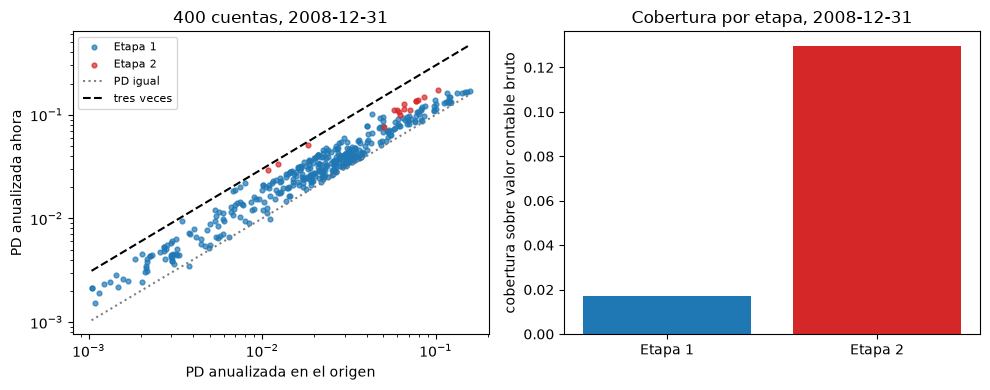

In [10]:
# Dibujar las 400 cuentas por PD anualizada de origen y actual, y la cobertura por etapa
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
for stage_no, color in ((1, "tab:blue"), (2, "tab:red")):
    mask = result.stage == stage_no
    left.scatter(orig[mask], now[mask], s=12, color=color, alpha=0.7, label="Etapa " + str(stage_no))
grid = np.array([orig.min(), orig.max()])
left.plot(grid, grid, color="grey", linestyle=":", label="PD igual")
left.plot(grid, 3.0 * grid, color="black", linestyle="--", label="tres veces")
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("PD anualizada en el origen")
left.set_ylabel("PD anualizada ahora")
left.set_title("400 cuentas, 2008-12-31")
left.legend(fontsize=8)

names = ["Etapa 1", "Etapa 2"]
right.bar(names, [rows["stage1"]["coverage"], rows["stage2"]["coverage"]], color=["tab:blue", "tab:red"])
right.set_ylabel("cobertura sobre valor contable bruto")
right.set_title("Cobertura por etapa, 2008-12-31")
fig.tight_layout()
plt.show()

## Resultados

- **Dos cuentas, una regla.** La cuenta A0001 de Etapa 1 tiene una PD anualizada de 0,0029 en el origen y 0,0034 ahora, una razón de 1,19: sin aumento significativo. La cuenta A0005 de Etapa 2 pasa de 0,0114 a 0,0306, una razón de 2,69 y una diferencia de 0,0192: su PD de origen cae en la banda cuyo multiplicador es 2,5, así que se cumplen la razón y el piso.
- **El motor reproduce las etapas versionadas.** En las 400 cuentas de la muestra, la etapa y el disparador de `allocate_stages` son iguales a los versionados: 384 cuentas en la Etapa 1 y 16 en la Etapa 2, las 16 por la regla relativa y absoluta (4 % de la muestra). El artefacto lo calculó el motor 0.5.0; el motor instalado ahora (0.8.1) da la misma asignación, que es la conciliación que hace la verificación.
- **El respaldo del triple nunca actúa aquí.** La mayor razón de la muestra es 2,76, así que ninguna cuenta está en tres veces o más, y la razón del triple cambia el conteo solo cuando se baja a 2 (35 cuentas). El piso absoluto tampoco pesa: el conteo es 16 con un piso de 0, 0,005 y 0,01 y 15 con 0,02.
- **El calendario de multiplicadores es la palanca.** Escalar todo el calendario por 0,75 lleva 109 cuentas a la Etapa 2, por 1,25 solo 2. Es la cantidad que un validador debe cuestionar, junto con su calibración a la PD de origen, y el umbral no debe relajarse cuando las condiciones empeoran (EBA/Rep/2023/36 párrafo 33).
- **Las reglas cualitativas son exactas en sus bordes.** 30 días de mora es Etapa 1 y 31 es Etapa 2 por el respaldo; 90 es Etapa 3; la refinanciación es Etapa 2; cuando valen dos razones, se reporta el disparador de mayor precedencia (la lista de vigilancia con 31 días se reporta como `dpd-backstop`). La exención de bajo riesgo de crédito suprimió el disparador relativo y absoluto de la cuenta cuya PD subió de 0,002 a 0,0082 y dejó intactos todos los casos de días de mora y de refinanciación.
- **Prueba y mirada colectiva.** Con una prueba de 12 meses, la cuenta curada hace 3 meses sigue en la Etapa 2 con el disparador `cure-probation`, y las curadas hace 12 y 20 meses vuelven a la Etapa 1. El objetivo colectivo es 400.000 para el segmento A (10 % de 4.000.000) y 1.500.000 para el segmento B (25 % de 6.000.000): montos para convertir en cuentas, nunca para sumar a la cobertura.
- **Un año de crisis y un año tranquilo.** En 2008, 12.407 de las 325.731 cuentas de Etapa 1 de apertura (3,81 %) pasaron a la Etapa 2, la Etapa 2 tuvo 1,1 % del monto bruto y su cobertura fue 12,97 % frente a 1,71 % de la Etapa 1, 7,59 veces mayor. Al 2019-12-31 ningún préstamo estaba en la Etapa 2 y la cobertura de la Etapa 1 era 0,58 %.

Lo que este cuaderno no muestra: el pipeline asigna etapas solo con la regla cuantitativa, porque el archivo no tiene historia de mora (hallazgo `F-NO-DELINQUENCY`), así que la Etapa 3 no tiene saldo en una fecha y los casos de días de mora son construidos. Las 400 cuentas son una muestra, y los flujos y resúmenes por etapa son los de toda la cartera. Si las etapas predicen los incumplimientos es una pregunta de validación, que responde el cuaderno 05.

## Resumen

- Las etapas comparan la PD de ahora con la PD en el origen sobre la misma ventana, ambas anualizadas, y el motor aplica una regla relativa y absoluta con un respaldo del triple; los parámetros son política, no regulación.
- `allocate_stages` devuelve la etapa y el disparador que decidió, con una precedencia fija: incumplimiento, días de mora, refinanciación, lista de vigilancia, colectivo, relativa y absoluta, triple. La exención de bajo riesgo de crédito toca solo los dos disparadores cuantitativos.
- En el C06 a la fecha de crisis las etapas del pipeline se reproducen exactamente, 16 de 400 cuentas de la muestra en la Etapa 2, y el calendario de multiplicadores, no el piso ni la razón del triple, decide cuántas.
- La prueba y la transferencia colectiva son funciones separadas: la primera mantiene un préstamo curado en la Etapa 2, la segunda solo reporta un monto objetivo.
- Los flujos entre etapas y la cobertura por etapa son lo que necesita una tabla de IFRS 7: la cobertura de la Etapa 2 fue 7,59 veces la de la Etapa 1 en 2008, y en 2019 no hubo Etapa 2.

**Qué probar a continuación.** Cambia `probation_months` a 6 y a 24, escala el calendario de multiplicadores por 0,5 (el motor lo rechazará: los multiplicadores deben ser al menos 1) y lee el mensaje. Después sigue con el cuaderno 03, que pondera los escenarios detrás de estas PD.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2021), IFRS 9 implementation by EU institutions, informe de seguimiento, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- Botha, A. y Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, ecuaciones 6 a 10. https://arxiv.org/abs/2507.15441